# 04 - Transformer model (module 3)


Fine-tuning a BERT-type model for multi-label emotion classification on GoEmotions (28 labels), then comparison with the linear baseline.

**Step 1 (this part):** environment, data loading, multi-hot labels, tokenizer choice and token length analysis.

Runs on **Google Colab with a GPU** (Runtime > Change runtime type > T4 GPU).

## 1. GPU check

In [15]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


## 2. Libraries and seed

In [16]:
!pip install -q transformers datasets

In [17]:
import os
import subprocess
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, set_seed

SEED = 42
set_seed(SEED)   # fixes the seeds of random, numpy and torch

print("transformers:", transformers.__version__)
print("pandas:", pd.__version__)

transformers: 5.22.1
pandas: 2.2.3


## 3. Data

We use the clean splits produced by `01_eda_simple.ipynb` (duplicates removed, labels at three levels).
The `data/` folder is not on GitHub, so the files are kept on Google Drive:
`MyDrive/ML_Project/data/processed/{train,validation,test}.parquet`.

If they are not there yet, the cell below clones the repository, runs `01_eda_simple.ipynb` and copies the files to Drive.
This way the transformer uses **exactly the same splits** as the baseline.

In [18]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ML_Project"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "processed")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results", "transformer")
os.makedirs(RESULTS_DIR, exist_ok = True)

# Set to True ONCE after the data module (01_eda_simple.ipynb) changes, run this cell, then set it back to False
FORCE_REGENERATE = False

if FORCE_REGENERATE or not os.path.exists(os.path.join(DATA_DIR, "train.parquet")):
    print("Regenerating the processed data from the repository...")
    repo = "/content/ML_Project"
    if os.path.exists(repo):
        subprocess.run(["git", "-C", repo, "pull"], check = True)   # get the latest version of 01
    else:
        subprocess.run(["git", "clone", "https://github.com/lucaperkins/ML_Project", repo], check = True)
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute",
                    "01_eda_simple.ipynb", "--output", "/tmp/01_executed.ipynb"],
                   cwd = os.path.join(repo, "notebooks"), check = True)
    shutil.copytree(os.path.join(repo, "data", "processed"), DATA_DIR, dirs_exist_ok = True)
else:
    print("Using the processed data already on Drive.")

print(sorted(os.listdir(DATA_DIR)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using the processed data already on Drive.
['test.parquet', 'train.parquet', 'validation.parquet']


In [19]:
df_train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
df_val = pd.read_parquet(os.path.join(DATA_DIR, "validation.parquet"))
df_test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

print("Train:", df_train.shape, "Validation:", df_val.shape, "Test:", df_test.shape)
df_train.head()

Train: (43190, 5) Validation: (5377, 5) Test: (5379, 5)


,id,text,labels_28,labels_ekman,labels_sentiment
0,eebbqej,My favourite food is anything I didn't have to...,[neutral],[neutral],[neutral]
1,ed00q6i,"Now if he does off himself, everyone will thin...",[neutral],[neutral],[neutral]
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,[anger],[anger],[negative]
3,ed7ypvh,To make her feel threatened,[fear],[fear],[negative]
4,ed0bdzj,Dirty Southern Wankers,[annoyance],[anger],[negative]


**Sanity check:** the sizes must match the summary of `01_eda_simple.ipynb` (43,190 / 5,377 / 5,379).
The test set is loaded only to check it, it is **not used** before the final evaluation.

In [20]:
assert len(df_train) == 43190 and len(df_val) == 5377 and len(df_test) == 5379, "Splits differ from 01_eda_simple.ipynb"

## 4. Multi-hot labels

Each comment becomes a vector of 28 values (1 if the label is present, 0 otherwise).
The label order is the **official GoEmotions order** and must be the same in the baseline notebook, otherwise the comparison per label is wrong.

The values are **float32**: the multi-label loss (binary cross-entropy) expects floats, not integers.

In [21]:
LABELS = ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion",
          "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment",
          "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "optimism",
          "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"]
assert len(LABELS) == 28

def to_multi_hot(label_lists, labels = LABELS):
    index = {name: i for i, name in enumerate(labels)}
    y = np.zeros((len(label_lists), len(labels)), dtype = np.float32)
    for row, names in enumerate(label_lists):
        for name in names:
            y[row, index[name]] = 1.0
    return y

y_train = to_multi_hot(df_train["labels_28"])
y_val = to_multi_hot(df_val["labels_28"])

print("y_train:", y_train.shape, y_train.dtype)
print("Every comment has at least one label:", bool((y_train.sum(axis = 1) >= 1).all()))
print("Comments with several labels:", round(100 * (y_train.sum(axis = 1) > 1).mean(), 1), "%")

y_train: (43190, 28) float32
Every comment has at least one label: True
Comments with several labels: 16.5 %


In [22]:
# check against the EDA: number of train comments per label
pd.Series(y_train.sum(axis = 0).astype(int), index = LABELS).sort_values(ascending = False)

,0
neutral,14183
admiration,4118
approval,2938
gratitude,2613
annoyance,2468
amusement,2327
curiosity,2187
love,2062
disapproval,2020
optimism,1578


## 5. Choice of the model and tokenizer

We use **`distilbert-base-cased`** (Sanh et al., 2019):
- **DistilBERT** is a smaller, faster version of BERT (about 40% smaller, 60% faster, keeping about 97% of BERT's language understanding according to its authors). It fits in the free Colab GPU and in our time budget.
- **Cased** keeps capital letters. The EDA showed that capitals and punctuation carry emotion (e.g. *"WHY THE FUCK IS BAYLESS ISOING"*), and an *uncased* model would lowercase everything and lose this signal.

In [23]:
MODEL_NAME = "distilbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

for text in ["WHY THE FUCK IS BAYLESS ISOING",
             "Thanks so much!! I really appreciate it",
             "I miss [NAME]",
             "This is amazing 😂😂"]:
    print(text)
    print("   ->", tokenizer.tokenize(text))

WHY THE FUCK IS BAYLESS ISOING
   -> ['W', '##H', '##Y', 'THE', 'F', '##UC', '##K', 'IS', 'BA', '##Y', '##LE', '##SS', 'ISO', '##ING']
Thanks so much!! I really appreciate it
   -> ['Thanks', 'so', 'much', '!', '!', 'I', 'really', 'appreciate', 'it']
I miss [NAME]
   -> ['I', 'miss', '[', 'N', '##AM', '##E', ']']
This is amazing 😂😂
   -> ['This', 'is', 'amazing', '[UNK]']


**What to look at:**
- Capitals give different tokens from lowercase words, so the signal is kept.
- `[NAME]` is split into several pieces. It is not a special token for the model.
- Emojis may become `[UNK]` (unknown token), so their emotional signal is lost. We measure how often this happens below.

## 6. Length in tokens

The EDA counted **words**. The model works on **tokens** (sub-words), so a text has more tokens than words.
We choose `MAX_LEN` (the maximum length given to the model) so that almost no text is truncated, while keeping it small: a shorter `MAX_LEN` means faster training.

Measured on **train only**.

In [24]:
encoded = tokenizer(list(df_train["text"]), add_special_tokens = True)["input_ids"]
n_tokens = pd.Series([len(ids) for ids in encoded])

print(n_tokens.describe().round(1))
for q in [0.95, 0.99, 1.0]:
    print(f"{int(q * 100)}% of texts have at most {int(n_tokens.quantile(q))} tokens")

count    43190.0
mean        20.2
std          9.2
min          3.0
25%         13.0
50%         20.0
75%         27.0
max        316.0
dtype: float64
95% of texts have at most 35 tokens
99% of texts have at most 41 tokens
100% of texts have at most 316 tokens


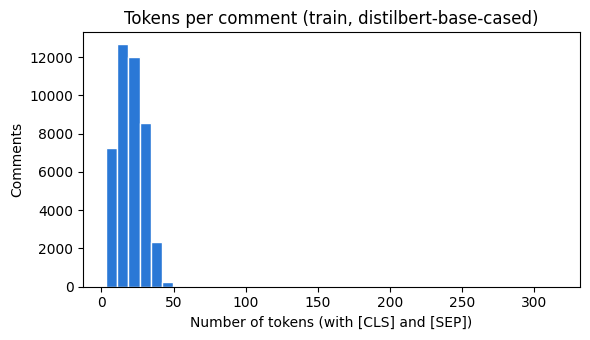

In [25]:
fig, ax = plt.subplots(figsize = (6, 3.5))
ax.hist(n_tokens, bins = 40, color = "#2a78d6", edgecolor = "white")
ax.set_title("Tokens per comment (train, " + MODEL_NAME + ")")
ax.set_xlabel("Number of tokens (with [CLS] and [SEP])")
ax.set_ylabel("Comments")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "token_length.png"))
plt.show()

In [26]:
for max_len in [32, 48, 64, 96, 128]:
    truncated = (n_tokens > max_len).mean()
    print(f"MAX_LEN = {max_len:>3}: {100 * truncated:.2f}% of train texts truncated")

MAX_LEN =  32: 10.17% of train texts truncated
MAX_LEN =  48: 0.22% of train texts truncated
MAX_LEN =  64: 0.03% of train texts truncated
MAX_LEN =  96: 0.01% of train texts truncated
MAX_LEN = 128: 0.00% of train texts truncated


In [27]:
# share of texts containing an unknown token
unk_id = tokenizer.unk_token_id
has_unk = pd.Series([unk_id in ids for ids in encoded])
print("Train texts with at least one [UNK] token:", round(100 * has_unk.mean(), 2), "%")
print("Examples:")
for t in df_train["text"][has_unk.values].head(5):
    print("  ", t)

Train texts with at least one [UNK] token: 2.01 %
Examples:
   Yes I heard abt the f bombs! That has to be why. Thanks for your reply:) until then hubby and I will anxiously wait 😝
   sorry [NAME]! 😘😘😘
   omg [NAME] and his dad walking out together is so cute 😍
   Lmao Stole my joke! 😂
   I always just say “thank you” because it’s a nice thought 🤷‍♀️


In [28]:
# inspect the longest texts in tokens
longest = n_tokens.sort_values(ascending = False).head(5)
for i, n in longest.items():
    print(n, "tokens:", df_train["text"].iloc[i][:150])

316 tokens: here you go: |Games|Home|Away|Team|vs W-L 18-19| |:-|:-|:-|:-|-:| |1|1|0|Golden State|0-1| |2|1|1|Houston|0-0| |2|1|1|Oklahoma City|0-0| |2|0|2|Toront
120 tokens: ackchyually, it's *r/woooosh ^^^^^I'm ^^^^^a ^^^^^bot. ^^^^^Complaints ^^^^^should ^^^^^be ^^^^^sent ^^^^^to ^^^^^u/stumblinbear ^^^^^where ^^^^^they 
99 tokens: >It also means no applause lines. No problem, just get the white house staff to clap for.... OHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHH
86 tokens: Oh fuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuck RIGHT OFF!!!!!
76 tokens: NO absolueltey wrong. WE MUST PRIORITIZE GETTING CORPORATE MONEY OUT OF POLITICS OR WE WILL NEVER BE ABLE TO SOLVE ANOTHER PROBLEM IN THIS COUNTRY.


## 7. Findings of step 1

- **Environment:** Tesla T4 GPU, PyTorch 2.14.1, transformers 5.22.1. The processed splits regenerated on Colab match `01_eda_simple.ipynb` exactly (43,190 / 5,377 / 5,379), so the transformer uses the same data as the baseline.
- **Labels:** 16.5% of train comments have several labels, which confirms the multi-label setting (sigmoid + binary cross-entropy, not softmax).
- **Token length:** median 20 tokens, 95% of texts under 35 and 99% under 41. The longest texts are not real long comments but Reddit artefacts: a Markdown table (316 tokens), a bot signature with superscript markers (120), words with repeated letters ("OHHHHHH", "fuuuuuuck", 86 to 99) and full-capital sentences (76). Truncating them at 64 tokens loses little emotional content.
- **Repeated letters:** they express intensity, but the tokenizer splits them into many meaningless pieces. Reducing repetitions to 3 letters is an option, to be decided with the data module and applied to the baseline as well.
- **Chosen `MAX_LEN` = 64:** it truncates only 0.03% of train texts. With dynamic padding, batches are padded to their longest text, so a larger `MAX_LEN` costs almost nothing.
- **Capital letters (correction of our first assumption):** the cased model keeps capitals, but words written fully in capitals are split into meaningless pieces ("WHY" -> W, ##H, ##Y). Cased is a trade-off, not a pure gain; cased vs uncased will be compared in step 3.
- **`[UNK]` tokens:** 2.01% of train texts, mostly emojis, which often carry strong emotion. Converting emojis to text is an option, to be applied to the baseline as well for a fair comparison.
- **`[NAME]` placeholder:** split into 5 sub-tokens. It will be added as a special token in step 2.

# Step 2: smoke test

Goal: check that the whole training pipeline works on a small sample (2,000 train / 500 validation comments, 1 epoch) before the real training in week 3. The scores are not meaningful here; we check the shapes, the loss, the saving, and the training time.

In [29]:
import re
import time
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import f1_score

# placeholders used by GoEmotions to mask names, religions, etc. (e.g. "[NAME]")
placeholders = pd.Series(re.findall(r"\[[A-Z]+\]", " ".join(df_train["text"]))).value_counts()
print(placeholders.head(10))

[NAME]        7645
[RELIGION]     100
[ALL]            1
[TEAM]           1
[T]              1
Name: count, dtype: int64


In [30]:
# keep only real placeholders (frequent), not rare brackets written by users
PLACEHOLDERS = [p for p in placeholders.index if placeholders[p] >= 20]
print("Placeholders kept:", PLACEHOLDERS)

n_added = tokenizer.add_tokens(PLACEHOLDERS, special_tokens = True)
print("Tokens added:", n_added, "-> vocabulary size:", len(tokenizer))
print(tokenizer.tokenize("I miss [NAME] so much"))

Placeholders kept: ['[NAME]', '[RELIGION]']
Tokens added: 2 -> vocabulary size: 28998
['I', 'miss', '[NAME]', 'so', 'much']


In [31]:
MAX_LEN = 64

class EmotionDataset(Dataset):
    """Holds texts and their multi-hot labels. Tokenization is done batch by batch."""
    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        return self.texts[i], self.labels[i]

def collate(batch):
    """Tokenizes one batch. padding=True pads to the longest text of the batch (dynamic padding)."""
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), padding = True, truncation = True,
                    max_length = MAX_LEN, return_tensors = "pt")
    enc["labels"] = torch.tensor(np.stack(labels), dtype = torch.float32)
    return enc

In [32]:
N_TRAIN_SMOKE = 2000   # small subset: the goal is to test the code, not to get good scores
N_VAL_SMOKE = 500
BATCH_SIZE = 32

rng = np.random.RandomState(SEED)
idx_train = rng.choice(len(df_train), N_TRAIN_SMOKE, replace = False)
idx_val = rng.choice(len(df_val), N_VAL_SMOKE, replace = False)

train_ds = EmotionDataset(df_train["text"].iloc[idx_train], y_train[idx_train])
val_ds = EmotionDataset(df_val["text"].iloc[idx_val], y_val[idx_val])

train_loader = DataLoader(train_ds, batch_size = BATCH_SIZE, shuffle = True, collate_fn = collate,
                          generator = torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size = 64, shuffle = False, collate_fn = collate)

example = next(iter(val_loader))
print({k: tuple(v.shape) for k, v in example.items()})

{'input_ids': (64, 39), 'token_type_ids': (64, 39), 'attention_mask': (64, 39), 'labels': (64, 28)}


In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = len(LABELS),
    problem_type = "multi_label_classification",   # one sigmoid per label, not a softmax
    id2label = dict(enumerate(LABELS)),
    label2id = {label: i for i, label in enumerate(LABELS)},
)
model.resize_token_embeddings(len(tokenizer))   # room for the new [NAME] / [RELIGION] tokens
model.to(device)
print("Device:", device, "| problem type:", model.config.problem_type, "| labels:", model.config.num_labels)

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.h

Device: cuda | problem type: multi_label_classification | labels: 28


In [34]:
loss_fn = torch.nn.BCEWithLogitsLoss()   # binary cross-entropy, one per label, on the raw logits

model.eval()
with torch.no_grad():
    batch = {k: v.to(device) for k, v in example.items()}
    logits = model(input_ids = batch["input_ids"], attention_mask = batch["attention_mask"]).logits
print("Logits shape:", tuple(logits.shape))
print("Loss before training:", round(loss_fn(logits, batch["labels"]).item(), 3), "(expected close to ln 2 = 0.693)")

Logits shape: (64, 28)
Loss before training: 0.693 (expected close to ln 2 = 0.693)


In [35]:
LEARNING_RATE = 5e-5
EPOCHS = 1
optimizer = torch.optim.AdamW(model.parameters(), lr = LEARNING_RATE)

model.train()
losses = []
start = time.time()
for epoch in range(EPOCHS):
    for step, batch in enumerate(train_loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        logits = model(input_ids = batch["input_ids"], attention_mask = batch["attention_mask"]).logits
        loss = loss_fn(logits, batch["labels"])

        optimizer.zero_grad()   # reset the gradients of the previous batch
        loss.backward()         # compute the gradients
        optimizer.step()        # update the weights

        losses.append(loss.item())
        if step % 10 == 0:
            print(f"epoch {epoch}  step {step:>3}  loss {loss.item():.4f}")
train_time = time.time() - start
print(f"Training time: {train_time:.0f} s for {N_TRAIN_SMOKE * EPOCHS} examples")

epoch 0  step   0  loss 0.6908
epoch 0  step  10  loss 0.4879
epoch 0  step  20  loss 0.3289
epoch 0  step  30  loss 0.2401
epoch 0  step  40  loss 0.1918
epoch 0  step  50  loss 0.1493
epoch 0  step  60  loss 0.1852
Training time: 7 s for 2000 examples


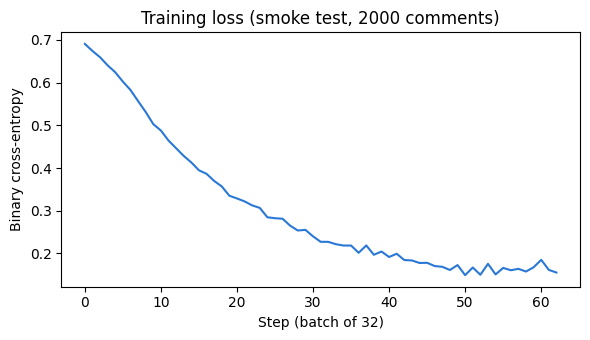

In [36]:
fig, ax = plt.subplots(figsize = (6, 3.5))
ax.plot(losses, color = "#2a78d6")
ax.set_title("Training loss (smoke test, " + str(N_TRAIN_SMOKE) + " comments)")
ax.set_xlabel("Step (batch of " + str(BATCH_SIZE) + ")")
ax.set_ylabel("Binary cross-entropy")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "smoke_test_loss.png"))
plt.show()

In [37]:
def predict_proba(model, loader):
    """Returns one probability per label (sigmoid of the logits), shape (n_texts, 28)."""
    model.eval()
    probs = []
    with torch.no_grad():
        for batch in loader:
            logits = model(input_ids = batch["input_ids"].to(device),
                           attention_mask = batch["attention_mask"].to(device)).logits
            probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.vstack(probs)

p_val = predict_proba(model, val_loader)
y_val_smoke = y_val[idx_val]
pred = (p_val >= 0.5).astype(int)   # fixed threshold for now; per-label thresholds come in step 3

print("Probabilities:", p_val.shape, "min", round(p_val.min(), 3), "max", round(p_val.max(), 3))
print("Mean number of predicted labels per text:", round(pred.sum(axis = 1).mean(), 2))
print("Texts with no predicted label:", round(100 * (pred.sum(axis = 1) == 0).mean(), 1), "%")
print("Labels predicted at least once:", [LABELS[j] for j in np.where(pred.sum(axis = 0) > 0)[0]])
print("Macro-F1:", round(f1_score(y_val_smoke, pred, average = "macro", zero_division = 0), 3))
print("Micro-F1:", round(f1_score(y_val_smoke, pred, average = "micro", zero_division = 0), 3))

Probabilities: (500, 28) min 0.023 max 0.311
Mean number of predicted labels per text: 0.0
Texts with no predicted label: 100.0 %
Labels predicted at least once: []
Macro-F1: 0.0
Micro-F1: 0.0


In [41]:
from sklearn.metrics import roc_auc_score

# 1) compare the final loss with a naive model that always predicts the label frequencies
freq = y_train[idx_train].mean(axis = 0)
p_naive = np.clip(freq, 1e-6, 1 - 1e-6)
naive_loss = -(freq * np.log(p_naive) + (1 - freq) * np.log(1 - p_naive)).mean()
print("Loss of the naive model (label frequencies):", round(naive_loss, 3))
print("Mean training loss over the last 10 steps:", round(np.mean(losses[-10:]), 3))

# 2) ROC AUC per label: does the model RANK texts correctly, whatever the threshold?
# 0.5 = random ranking, 1.0 = perfect ranking. Labels absent from the sample are skipped.
present = y_val_smoke.sum(axis = 0) > 0
auc = roc_auc_score(y_val_smoke[:, present], p_val[:, present], average = None)
auc_per_label = pd.Series(auc, index = np.array(LABELS)[present]).sort_values(ascending = False)
print(auc_per_label.round(2))
print("Mean AUC:", round(auc_per_label.mean(), 3))

Loss of the naive model (label frequencies): 0.15
Mean training loss over the last 10 steps: 0.165
curiosity         0.74
gratitude         0.74
neutral           0.68
nervousness       0.66
relief            0.66
confusion         0.64
anger             0.63
optimism          0.61
admiration        0.60
excitement        0.58
caring            0.58
surprise          0.56
remorse           0.56
annoyance         0.55
pride             0.54
realization       0.52
disapproval       0.50
fear              0.49
love              0.49
approval          0.49
joy               0.47
desire            0.46
embarrassment     0.45
amusement         0.43
disappointment    0.36
disgust           0.35
sadness           0.30
grief             0.01
dtype: float64
Mean AUC: 0.523


In [38]:
seconds_per_example = train_time / (N_TRAIN_SMOKE * EPOCHS)
full_epoch_minutes = seconds_per_example * len(df_train) / 60
print(f"Estimated time for one epoch on the full train set ({len(df_train)} comments): {full_epoch_minutes:.0f} min")
print(f"Estimated time for 3 epochs: {3 * full_epoch_minutes:.0f} min")

Estimated time for one epoch on the full train set (43190 comments): 3 min
Estimated time for 3 epochs: 8 min


In [39]:
SMOKE_DIR = os.path.join(PROJECT_DIR, "models", "smoke_test")
model.save_pretrained(SMOKE_DIR)
tokenizer.save_pretrained(SMOKE_DIR)

reloaded = AutoModelForSequenceClassification.from_pretrained(SMOKE_DIR).to(device)
reloaded_tokenizer = AutoTokenizer.from_pretrained(SMOKE_DIR)
p_reloaded = predict_proba(reloaded, val_loader)

print("Same predictions after reload:", np.allclose(p_val, p_reloaded, atol = 1e-5))
print("Reloaded tokenizer keeps [NAME]:", reloaded_tokenizer.tokenize("I miss [NAME]"))
print("Reloaded config:", reloaded.config.problem_type, reloaded.config.num_labels)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Same predictions after reload: True
Reloaded tokenizer keeps [NAME]: ['I', 'miss', '[NAME]']
Reloaded config: multi_label_classification 28


In [40]:
# free the GPU memory before the next experiments
del reloaded
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [42]:
# sanity check: can the model memorise 64 TRAIN comments? The loss should fall far below the naive 0.15
small = next(iter(DataLoader(train_ds, batch_size = 64, shuffle = False, collate_fn = collate)))
small = {k: v.to(device) for k, v in small.items()}

overfit_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels = len(LABELS), problem_type = "multi_label_classification")
overfit_model.resize_token_embeddings(len(tokenizer))
overfit_model.to(device)
opt = torch.optim.AdamW(overfit_model.parameters(), lr = LEARNING_RATE)

overfit_model.train()
for step in range(150):
    logits = overfit_model(input_ids = small["input_ids"], attention_mask = small["attention_mask"]).logits
    loss = loss_fn(logits, small["labels"])
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 25 == 0 or step == 149:
        print(f"step {step:>3}  loss {loss.item():.4f}")

del overfit_model, opt
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   0  loss 0.7039
step  25  loss 0.2639
step  50  loss 0.1621
step  75  loss 0.1260
step 100  loss 0.0786
step 125  loss 0.0472
step 149  loss 0.0297


## 9. Findings of step 2

- **Placeholders:** `[NAME]` (7,645 occurrences in train) and `[RELIGION]` (100) are added as special tokens. One-off brackets such as `[ALL]`, `[TEAM]` or `[T]` (1 occurrence each) are left out by the threshold of 20. `[NAME]` is now a single token instead of five.
- **Model loading:** the "UNEXPECTED" weights (the original word-prediction head) are dropped and the "MISSING" weights (`pre_classifier`, `classifier`) are newly initialised. This is expected: the language-model head is replaced by a 28-output classification head that we train.
- **Loss before training:** 0.693 = ln 2, as expected for 28 independent sigmoids around 0.5. This confirms the multi-label setup (sigmoid + binary cross-entropy, not softmax).
- **Loss after 1 epoch on 2,000 comments:** from 0.69 to 0.165, while a naive model that always predicts the label frequencies reaches 0.15. After this tiny run, the model has only learned that emotions are rare. A decreasing loss alone does not prove useful learning; it must be compared with this naive reference.
- **Predictions at threshold 0.5:** the highest probability is 0.31, so no label is predicted and macro-F1 = micro-F1 = 0. A fixed 0.5 threshold does not work with rare labels, which motivates per-label thresholds tuned on the validation set (step 3).
- **Ranking quality (ROC AUC, threshold-free):** mean AUC 0.523, close to random (0.5). Only curiosity (0.74) and gratitude (0.74) are clearly above chance, which matches the strongest cues found in the EDA ("?" and "thanks"). This also shows that texts and labels are correctly aligned. Very low values (grief 0.01, sadness 0.30) rely on one or a few examples in the 500-comment sample and are not interpretable: per-label scores must always be reported with their number of examples.
- **Memorisation test (64 train comments, 150 steps):** the loss falls from 0.70 to 0.030, far below the naive 0.15. The model and the optimisation work; the weak smoke-test scores come from the tiny amount of data and training, not from a bug.
- **Training time:** 7 s for 2,000 comments on a Tesla T4, so about 3 min per full epoch (about 8 min for 3 epochs). Full training is cheap, so we can afford several runs in step 3: several seeds (to report mean and standard deviation), cased vs uncased, and a weighted loss for rare emotions.
- **Save and reload:** the reloaded model gives identical predictions, and keeps the `[NAME]` token and the multi-label configuration.

**Conclusion:** the full pipeline (tokenization with dynamic padding, multi-label model, training loop, prediction, saving) is validated. Real training and evaluation start in step 3, once the final data (module 1) and the baseline (module 2) are ready.